##Spectral Localiser

In [1]:
using SparseArrays, LinearAlgebra, ProgressMeter, DataFrames, KrylovKit, LDLFactorizations
using LaTeXStrings
using Measures
using Plots

In [21]:

## Efficient localiser gap compute
function compute_localiser_gap_Krylov(
    L::Union{SparseMatrixCSC{Float64, Int}, Matrix};
    kk_tol::Real=1e-8,
    kk_maxiter::Int=1000
)::Float64

    L2_action(x) = L * (L * x) # matrix-free action for L^2. 
    n = size(L, 1)
    
    # We ask KrylovKit for 1 eigenvalue (:SR = Smallest Real).
    evals, evecs, info = eigsolve(L2_action, rand(Float64, n), 1, :SR; 
                                  ishermitian=true, tol=kk_tol, maxiter=kk_maxiter)
    
    localiser_gap = sqrt(abs(evals[1]))
    return localiser_gap
end

## Efficient winding number compute (1D BDI class)
function compute_winding_signature_LDLT(
    L::Union{SparseMatrixCSC{Float64, Int}, Matrix};
)::Float64

    # # 1. Unlike 2D, the 1D Kitaev localiser is natively purely real and symmetric!
    # # No need for the 2Nx2N complex-to-real isomorphism trick.
    # ldl_fact = ldl(Symmetric(L))
    
    # # 2. Extract the diagonal matrix D (.d)
    # D_diag = ldl_fact.d
    
    # # 3. Count the positive and negative entries
    # n_pos = count(x -> x > 0, D_diag)
    # n_neg = count(x -> x < 0, D_diag)
    
    # # 4. Calculate the invariant (1/2 signature for 1D chiral systems)
    # winding = (n_pos - n_neg) / 2.0

    vals = eigvals(Matrix(L))
    sig = count(vals .> 0) - count(vals .< 0)

    winding = sig / 2.0
    
    return winding
end

## Auxiliary functions
# Build position and chiral operators
function build_operators_kitaev(Lx::Int)
    dim = 2 * Lx
    xvec = zeros(Float64, dim)
    
    # For sparse construction of Gamma (Chiral symmetry sigma_x)
    gamma_row = Int[]
    gamma_col = Int[]
    gamma_val = Float64[]
    
    for x in 1:Lx
        base = 2 * (x - 1)
        xvec[base + 1] = x
        xvec[base + 2] = x
        
        # Sigma_x connects the two orbitals on the same site
        push!(gamma_row, base + 1, base + 2)
        push!(gamma_col, base + 2, base + 1)
        push!(gamma_val, 1.0, 1.0)
    end
    
    X = Diagonal(xvec)
    Gamma = sparse(gamma_row, gamma_col, gamma_val, dim, dim)
    
    return X, Gamma
end

# Real-space BdG Hamiltonian for 1D Kitaev chain
function real_space_hamiltonian_kitaev(
    Lx::Int;
    t::Real=1.0,
    Delta::Real=1.0,
    mu::Real=0.0,
    periodic::Bool=false,
    sparse_output::Bool=true
)
    Lx > 0 || error("Lx must be positive.")
    dim = 2 * Lx

    # 2x2 blocks based on the BdG basis (c, c^dagger)
    onsite = [-mu 0.0; 
               0.0 mu]
               
    hop = [-t  Delta; 
           -Delta t]
           
    hop_adj = [-t -Delta; 
                Delta t]

    H = sparse_output ? spzeros(Float64, dim, dim) : zeros(Float64, dim, dim)

    function add_block!(mat, r::Int, c::Int, block::Matrix{Float64})
        r_base = 2 * (r - 1)
        c_base = 2 * (c - 1)
        for a in 1:2, b in 1:2
            mat[r_base + a, c_base + b] += block[a, b]
        end
    end

    for x in 1:Lx
        add_block!(H, x, x, onsite)

        if x < Lx
            add_block!(H, x, x + 1, hop)
            add_block!(H, x + 1, x, hop_adj)
        elseif periodic
            add_block!(H, Lx, 1, hop)
            add_block!(H, 1, Lx, hop_adj)
        end
    end

    return H
end

# Wrapper function over parameter ranges
function compute_spec_loc_df_kitaev(
    Lx::Int; 
    tvals::AbstractVector{<:Real} = [1.0], 
    Deltavals::AbstractVector{<:Real} = [1.0], 
    muvals::AbstractVector{<:Real} = [0.0],
    xs::AbstractVector = collect(1:Lx), 
    kappas::AbstractVector{<:Real} = [1.0],
    periodic::Bool=false, 
    sparse_output::Bool=true,
    kk_tol::Real=1e-8,
    kk_maxiter::Int=1000,
    gap_tol::Real=1e-6
)::DataFrame

    rows = Vector{NamedTuple{
        (:t, :Delta, :mu, :Lx, :x, :kappa, :localiser_gap, :winding_number),
        Tuple{Float64,Float64,Float64,Int64,Float64,Float64,Float64,Union{Missing, Float64}}
    }}()

    @showprogress for t in tvals, Delta in Deltavals, mu in muvals

        H = real_space_hamiltonian_kitaev(Lx; t=t, Delta=Delta, mu=mu, periodic=periodic, sparse_output=sparse_output)
        X, Gamma = build_operators_kitaev(Lx)

        for x0 in xs, kappa in kappas
            
            # X - x0 is diagonal, allowing fast vectorized math
            X_diff = sparse(Diagonal(X.diag .- x0))
            
            # Assemble the 1D Spectral localiser
            # Multiplications between perfectly sparse structurally symmetric matrices
            L = kappa .* (Gamma * X_diff) + H

            gap = compute_localiser_gap_Krylov(L; kk_tol=kk_tol, kk_maxiter=kk_maxiter)
            winding_val = compute_winding_signature_LDLT(L)
            
            # If the localiser gap closes, treat invariant as ill-defined (missing)
            winding_number = if gap <= gap_tol
                missing
            else
                winding_val
            end
            
            push!(rows, (
                t=Float64(t), Delta=Float64(Delta), mu=Float64(mu), 
                Lx=Lx, 
                x=Float64(x0), 
                kappa=Float64(kappa),
                localiser_gap=gap,
                winding_number=winding_number
            ))
        end
    end

    return DataFrame(rows)
end

compute_spec_loc_df_kitaev (generic function with 1 method)

In [3]:
L = 100
t_vals = [1.0]
Delta_vals = [1.0]
mu_vals = collect(range(-4.0, 4.0, length=50))
kappa_vals = logrange(1e-10, 1e2, length=13)

df_results = compute_spec_loc_df_kitaev(
    L; 
    tvals=t_vals, 
    Deltavals=Delta_vals, 
    muvals=mu_vals, 
    xs=[1.0, 1.5, 50.5, 50.0, 100.0], 
    kappas=kappa_vals, 
    periodic=false, 
    sparse_output=true, 
    kk_tol=1e-8, 
    kk_maxiter=1000, 
    gap_tol=1e-6
)

println("Computed DataFrame of results:")


Computed DataFrame of results:


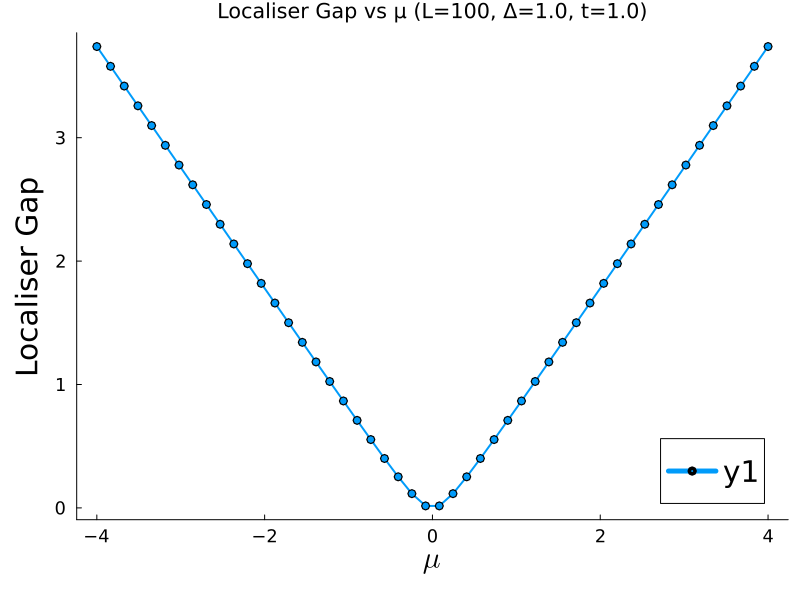

In [4]:
function plot_localiser_gap_vs_mu(
    df::DataFrame, 
    L::Int, 
    Delta::Float64, 
    t::Float64, 
    x::Float64, 
    kappa::Float64,
    filepath::String
)

    # Filter the DataFrame for the specified parameters
    df_filtered = filter(row -> row.Lx == L && row.Delta == Delta && row.t == t && row.x == x && row.kappa == kappa, df)

    # Sort by mu for plotting
    sort!(df_filtered, :mu)

    # Create the plot
    plt = Plots.plot(
        df_filtered.mu, 
        df_filtered.localiser_gap, 
        xlabel=L"\mu", 
        ylabel="Localiser Gap", 
        title="Localiser Gap vs μ (L=$L, Δ=$Delta, t=$t)", 
        lw=2,
        marker=:o,
        grid=false,
        size=(800, 600),
        labelfontsize=20,
        tickfontsize=12,
        legendfontsize=20,
        left_margin=5mm,
        bottom_margin=5mm
    )

    # Save the plot
    # Plots.savefig(plt, filepath)
    display(plt)
end

# Example usage:
L = 100
Delta = 1.0
t = 1.0
x0 = 1.0 #Int(L/2)
kappa = 1e1
filepath = "/Users/Will/Documents/Quasicrystal_Majorana_project_clone/Quasicrystal_Majorana_project/plots_masters_thesis/report_plots/localiser_gap/localiser_gap_vs_mu_L$(L)_Delta$(Delta)_t$(t)_kappa$(kappa).png"
plot_localiser_gap_vs_mu(df_results, L, Delta, t, x0, kappa, filepath)

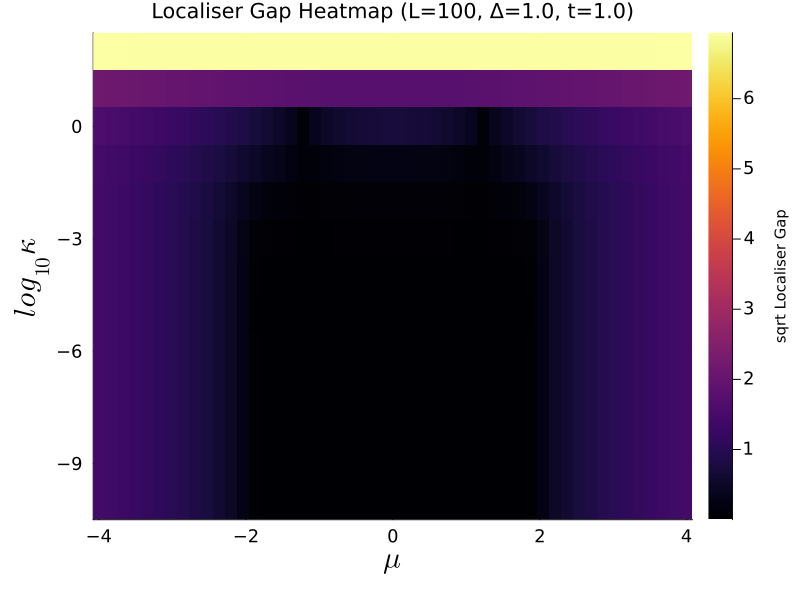

In [5]:
function heatmap_localiser_gap_vs_mu_kappa(
    df::DataFrame, 
    L::Int, 
    Delta::Float64, 
    t::Float64, 
    x::Float64,
    filepath::String
)
    # Filter the DataFrame for the specified parameters
    df_filtered = filter(row -> row.Lx == L && row.Delta == Delta && row.t == t && row.x == x, df)

    # # Create a pivot table for heatmap plotting
    # pivot_df = unstack(df_filtered, :kappa, :mu, :localiser_gap)

    # Extract mu and kappa values for axes
    mu_values = unique(df_filtered.mu)
    kappa_values = unique(df_filtered.kappa)
    # println("kappa_values: ", kappa_values)

    kappa_values=log10.(kappa_values)
    localiser_gap = reshape(df_filtered.localiser_gap, length(kappa_values), length(mu_values))
    log_localiser_gap = log10.(localiser_gap)
    sqrt_localiser_gap = sqrt.(localiser_gap)

    # Create the heatmap
    plt = Plots.heatmap(
        mu_values, 
        kappa_values, 
        sqrt_localiser_gap, 
        xlabel=L"\mu", 
        ylabel=L"log_{10}\kappa", 
        title="Localiser Gap Heatmap (L=$L, Δ=$Delta, t=$t)", 
        colorbar_title="sqrt Localiser Gap",
        size=(800, 600),
        labelfontsize=20,
        tickfontsize=12,
        legendfontsize=20,
        left_margin=5mm,
        bottom_margin=5mm
    )

    # Save the heatmap
    Plots.savefig(plt, filepath)
    display(plt)
end

# Example usage:
L = 100
Delta = 1.0
t = 1.0
x0 = 1.5 #Int(L/2)
filepath_heatmap = "heatmap_localiser_gap_vs_mu_kappa_L$(L)_Delta$(Delta)_t$(t)_x$(x0).png"
heatmap_localiser_gap_vs_mu_kappa(df_results, L, Delta, t, x0, filepath_heatmap)

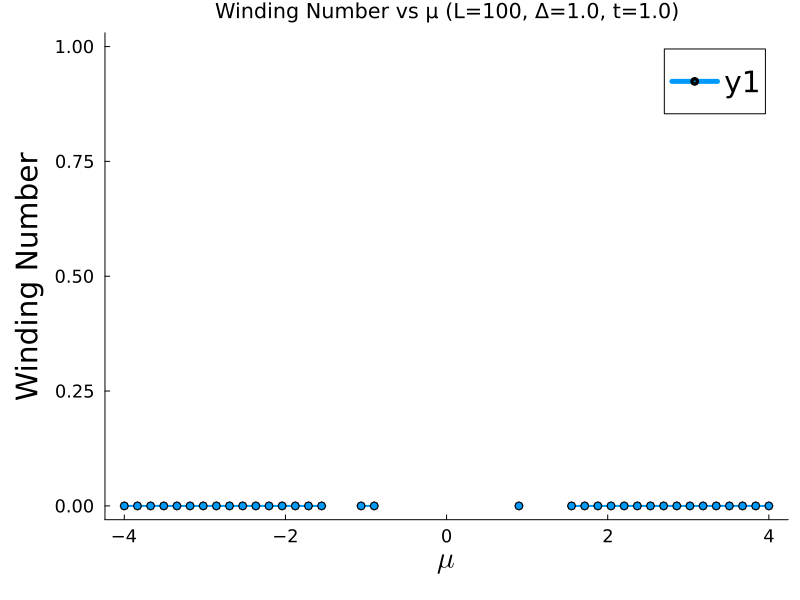

In [6]:
function plot_localiser_invariant_vs_mu(
    df::DataFrame, 
    L::Int, 
    Delta::Float64, 
    t::Float64, 
    x::Float64, 
    kappa::Float64,
    filepath::String
)

    # Filter the DataFrame for the specified parameters
    df_filtered = filter(row -> row.Lx == L && row.Delta == Delta && row.t == t && row.x == x && row.kappa == kappa, df)

    # Sort by mu for plotting
    sort!(df_filtered, :mu)

    # Create the plot
    plt = Plots.plot(
        df_filtered.mu, 
        df_filtered.winding_number, 
        xlabel=L"\mu", 
        ylabel="Winding Number", 
        title="Winding Number vs μ (L=$L, Δ=$Delta, t=$t)", 
        lw=2,
        marker=:o,
        grid=false,
        size=(800, 600),
        labelfontsize=20,
        tickfontsize=12,
        legendfontsize=20,
        left_margin=5mm,
        bottom_margin=5mm,
        # ylims=(-3, 3)
    )

    # Save the plot
    # Plots.savefig(plt, filepath)
    display(plt)
end


# Example usage:
L = 100
Delta = 1.0
t = 1.0
filepath = "/Users/Will/Documents/Quasicrystal_Majorana_project_clone/Quasicrystal_Majorana_project/plots_masters_thesis/report_plots/localiser_invariant/localiser_invariant_vs_mu_L$(L)_Delta$(Delta)_t$(t).png"
x0 = 1.0 #Int(L/2)
kappa = 1e-6
plot_localiser_invariant_vs_mu(df_results, L, Delta, t, x0, kappa, filepath)

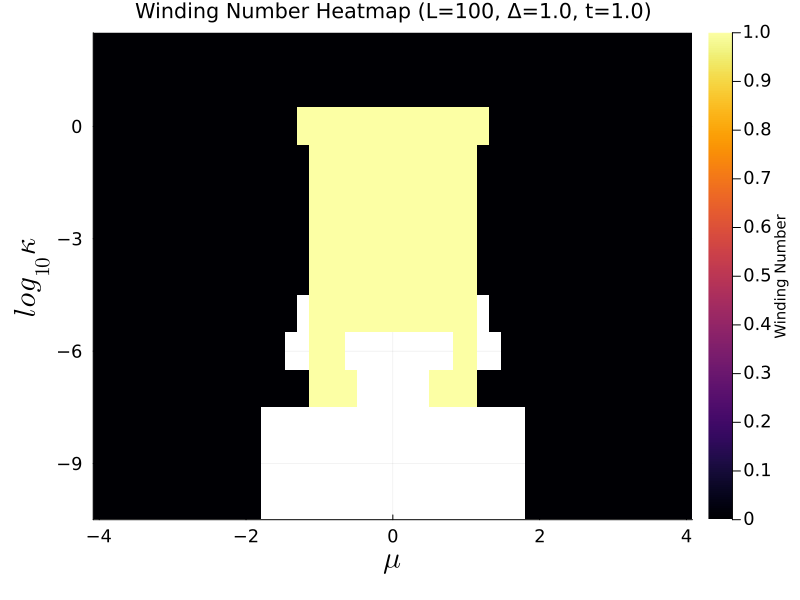

In [7]:
function heatmap_localiser_invariant_vs_mu_kappa(
    df::DataFrame, 
    L::Int, 
    Delta::Float64, 
    t::Float64, 
    x::Float64,
    filepath::String
)
    # Filter the DataFrame for the specified parameters
    df_filtered = filter(row -> row.Lx == L && row.Delta == Delta && row.t == t && row.x == x, df)

    # Extract mu and kappa values for axes
    mu_values = unique(df_filtered.mu)
    kappa_values = unique(df_filtered.kappa)

    kappa_values=log10.(kappa_values)
    winding_number = reshape(df_filtered.winding_number, length(kappa_values), length(mu_values))

    # Create the heatmap
    plt = Plots.heatmap(
        mu_values, 
        kappa_values, 
        winding_number, 
        xlabel=L"\mu", 
        ylabel=L"log_{10}\kappa", 
        title="Winding Number Heatmap (L=$L, Δ=$Delta, t=$t)", 
        colorbar_title="Winding Number",
        size=(800, 600),
        labelfontsize=20,
        tickfontsize=12,
        legendfontsize=20,
        left_margin=5mm,
        bottom_margin=5mm
    )

    # Save the heatmap
    Plots.savefig(plt, filepath)
    display(plt)
end

# Example usage:
L = 100
Delta = 1.0
t = 1.0
x0 = 1.5 #Int(L/2)
filepath_heatmap_invariant = "heatmap_localiser_invariant_vs_mu_kappa_L$(L)_Delta$(Delta)_t$(t)_x$(x0).png"
heatmap_localiser_invariant_vs_mu_kappa(df_results, L, Delta, t, x0, filepath_heatmap_invariant)

In [8]:
L = 100
t_vals = [1.0]
Delta_vals = [1.0]
mu_vals = collect(range(-4.0, 4.0, length=50))
kappa_vals = [1e-3] #logrange(1e-10, 1e2, length=13)

df_results = compute_spec_loc_df_kitaev(
    L; 
    tvals=t_vals, 
    Deltavals=Delta_vals, 
    muvals=mu_vals, 
    xs=collect(range(0.0, L, length=200)), 
    kappas=kappa_vals, 
    periodic=false, 
    sparse_output=true, 
    kk_tol=1e-8, 
    kk_maxiter=1000, 
    gap_tol=1e-6
)

println("Computed DataFrame of results:")

Computed DataFrame of results:


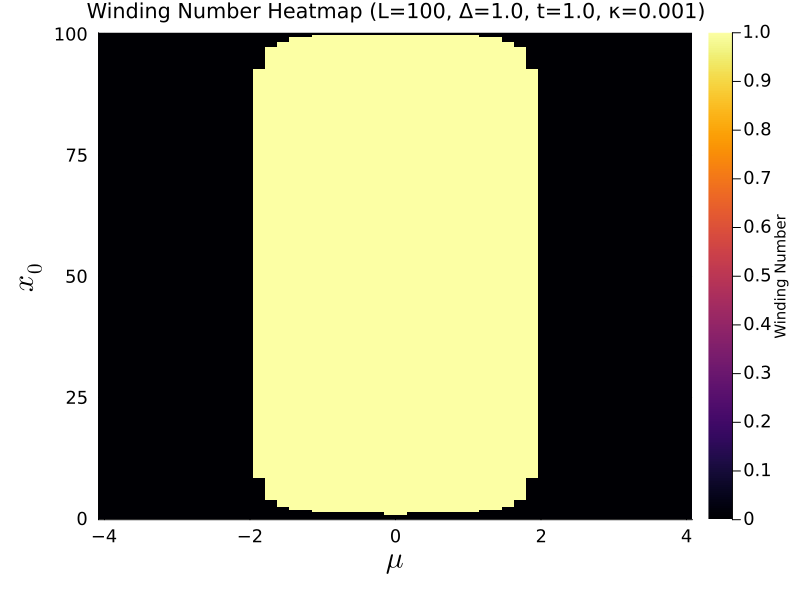

In [9]:
function heatmap_localiser_invariant_vs_mu_x0(
    df::DataFrame, 
    L::Int, 
    Delta::Float64, 
    t::Float64, 
    kappa::Float64,
    filepath::String
)
    # Filter the DataFrame for the specified parameters
    df_filtered = filter(row -> row.Lx == L && row.Delta == Delta && row.t == t && row.kappa == kappa, df)

    # Extract mu and x values for axes
    mu_values = unique(df_filtered.mu)
    x_values = unique(df_filtered.x)

    winding_number = reshape(df_filtered.winding_number, length(x_values), length(mu_values))

    # Create the heatmap
    plt = Plots.heatmap(
        mu_values, 
        x_values, 
        winding_number, 
        xlabel=L"\mu", 
        ylabel=L"x_0", 
        title="Winding Number Heatmap (L=$L, Δ=$Delta, t=$t, κ=$kappa)", 
        colorbar_title="Winding Number",
        size=(800, 600),
        labelfontsize=20,
        tickfontsize=12,
        legendfontsize=20,
        left_margin=5mm,
        bottom_margin=5mm
    )

    # Save the heatmap
    Plots.savefig(plt, filepath)
    display(plt)
end

# Example usage:
L = 100
Delta = 1.0
t = 1.0
kappa = 1e-3
filepath_heatmap_invariant_x0 = "heatmap_localiser_invariant_vs_mu_x0_L$(L)_Delta$(Delta)_t$(t)_kappa$(kappa).png"
heatmap_localiser_invariant_vs_mu_x0(df_results, L, Delta, t, kappa, filepath_heatmap_invariant_x0)

## Quasicrystal

In [14]:
function cut_and_project_sequence(N::Int, slope::Float64; phason::Float64=0.0, map_to::Tuple{Int,Int}=(1,2))
    @assert N >= 1 "N must be >= 1"
    # @assert 0.0 < alpha < 1.0 "alpha expected in (0,1) for standard Sturmian words"
    phason = phason - floor(phason) # wrap into [0,1)
    seq = Vector{Int}(undef, N)
    frac = phason
    for n in 1:N
        frac += slope
        if frac >= 1.0
            frac -= 1.0
            # crossing an integer -> difference = 1
            seq[n] = map_to[1]   # "A"
        else
            seq[n] = map_to[2]   # "B"
        end
    end
    return seq
end

N=1000
slope = 2/(1+sqrt(5))
phason = 0.0
map_to = (1,2)
seq = cut_and_project_sequence(N, slope; phason=phason, map_to=map_to)

println("Generated cut-and-project sequence of length $N with slope $slope and phason $phason.")

Generated cut-and-project sequence of length 1000 with slope 0.6180339887498948 and phason 0.0.


In [124]:
function create_qc_bdg_hamiltonian(
    N::Int, 
    t_n::Vector,
    mu::Float64, 
    Delta::Float64,
    sequence::Vector
)
    # Build in INTERLEAVED basis: (c_1, c_1†, c_2, c_2†, ..., c_N, c_N†)
    # to match the basis used by build_operators_kitaev
    dim = 2 * N
    BdG = zeros(Float64, dim, dim)
    
    # Use the same block structure as real_space_hamiltonian_kitaev
    # 2x2 blocks based on the BdG basis (c, c^dagger) at each site
    onsite = [-mu 0.0; 
               0.0 mu]
    
    function add_block!(mat, r::Int, c::Int, block::Matrix{Float64})
        r_base = 2 * (r - 1)
        c_base = 2 * (c - 1)
        for a in 1:2, b in 1:2
            mat[r_base + a, c_base + b] += block[a, b]
        end
    end
    
    # Add onsite terms and nearest-neighbor hopping
    for i in 1:N
        add_block!(BdG, i, i, onsite)
        
        if i < N
            # Get hopping amplitude from sequence
            hopping_index = sequence[i]
            t_hop = t_n[hopping_index]
            
            # Hopping block from site i to i+1
            hop = [-t_hop  Delta; 
                   -Delta  t_hop]
            
            # Adjoint hopping block from site i+1 to i
            hop_adj = [-t_hop -Delta; 
                        Delta  t_hop]
            
            add_block!(BdG, i, i+1, hop)
            add_block!(BdG, i+1, i, hop_adj)
        end
    end
    
    return BdG
end

# QC-specific wrapper function over parameter ranges
function qc_compute_spec_loc_df_kitaev(
    Lx::Int; 
    sequence::Vector{Int},
    t_n::Vector{<:Real} = [1.0, 2.0],
    Deltavals::AbstractVector{<:Real} = [1.0], 
    muvals::AbstractVector{<:Real} = [0.0],
    xs::AbstractVector = collect(1:Lx), 
    kappas::AbstractVector{<:Real} = [1.0],
    periodic::Bool=false, 
    sparse_output::Bool=true,
    kk_tol::Real=1e-8,
    kk_maxiter::Int=1000,
    gap_tol::Real=1e-6
)::DataFrame

    rows = Vector{NamedTuple{
        (:t_n, :Delta, :mu, :Lx, :x, :kappa, :localiser_gap, :winding_number),
        Tuple{Vector{Float64},Float64,Float64,Int64,Float64,Float64,Float64,Union{Missing, Float64}}
    }}()

    @showprogress for Delta in Deltavals, mu in muvals

        H = create_qc_bdg_hamiltonian(Lx, t_n, mu, Delta, sequence)
        X, Gamma = build_operators_kitaev(Lx)

        for x0 in xs, kappa in kappas
            
            # X - x0 is diagonal, allowing fast vectorized math
            X_diff = sparse(Diagonal(X.diag .- x0))
            
            # Assemble the 1D Spectral localiser
            # Multiplications between perfectly sparse structurally symmetric matrices
            L = kappa .* (Gamma * X_diff) + H

            gap = compute_localiser_gap_Krylov(L; kk_tol=kk_tol, kk_maxiter=kk_maxiter)
            winding_val = compute_winding_signature_LDLT(L)
            
            # If the localiser gap closes, treat invariant as ill-defined (missing)
            winding_number = if gap <= gap_tol
                missing
            else
                winding_val
            end
            
            push!(rows, (
                t_n=Float64.(t_n), Delta=Float64(Delta), mu=Float64(mu), 
                Lx=Lx, 
                x=Float64(x0), 
                kappa=Float64(kappa),
                localiser_gap=gap,
                winding_number=winding_number
            ))
        end
    end

    return DataFrame(rows)
end

qc_compute_spec_loc_df_kitaev (generic function with 1 method)

In [125]:
## Block Basis Spectral Localiser Implementation
# This cell contains functions for computing spectral localiser with block basis Hamiltonians
# Block basis ordering: (c_1, c_2, ..., c_N, c_1†, c_2†, ..., c_N†)

function build_operators_block_basis(N::Int)
    """
    Build position and chiral operators for BLOCK basis BdG Hamiltonian.
    Block basis ordering: (c_1, c_2, ..., c_N, c_1†, c_2†, ..., c_N†)
    
    X = diag(1, 2, ..., N, 1, 2, ..., N)  - position operator
    Γ = [0   I_N]  - chiral symmetry operator (particle-hole exchange)
        [I_N  0 ]
    """
    dim = 2 * N
    
    # Position operator X: diagonal with site indices
    xvec = zeros(Float64, dim)
    for i in 1:N
        xvec[i] = i        # particle at site i
        xvec[N + i] = i    # hole at site i
    end
    X = Diagonal(xvec)
    
    # Chiral symmetry Γ: block off-diagonal structure
    # Top-right block: I_N, Bottom-left block: I_N
    Gamma = spzeros(Float64, dim, dim)
    for i in 1:N
        Gamma[i, N + i] = 1.0      # particle to hole
        Gamma[N + i, i] = 1.0      # hole to particle
    end
    
    return X, Gamma
end

function np_create_bdg_hamiltonian(
    N::Int, 
    t_n::Vector,
    mu::Float64, 
    Delta::Float64,
    sequence::Vector
)
    
    H0 = zeros(Complex{Float64}, N, N)
    for i in 1:N-1
        H0[i, i] = -mu
        hopping_index = sequence[i]
        H0[i, i+1] = -t_n[hopping_index]
        H0[i+1, i] = -t_n[hopping_index]
    end
    H0[N, N] = -mu

    Delta_matrix = zeros(Complex{Float64}, N, N)
    for i in 1:N-1
        Delta_matrix[i, i+1] = Delta
        Delta_matrix[i+1, i] = -Delta
    end

    BdG = zeros(Complex{Float64}, 2N, 2N)
    BdG[1:N, 1:N] = H0
    BdG[N+1:end, N+1:end] = -conj(H0)
    BdG[1:N, N+1:end] = Delta_matrix
    BdG[N+1:end, 1:N] = Delta_matrix'

    return BdG
end

# Wrapper function for spectral localiser using BLOCK BASIS
# Use this with create_qc_bdg_hamiltonian (block basis Hamiltonian)
function qc_compute_spec_loc_df_block_basis(
    Lx::Int; 
    sequence::Vector{Int},
    t_n::Vector{<:Real} = [1.0, 2.0],
    Deltavals::AbstractVector{<:Real} = [1.0], 
    muvals::AbstractVector{<:Real} = [0.0],
    xs::AbstractVector = collect(1:Lx), 
    kappas::AbstractVector{<:Real} = [1.0],
    periodic::Bool=false, 
    sparse_output::Bool=true,
    kk_tol::Real=1e-8,
    kk_maxiter::Int=1000,
    gap_tol::Real=1e-6
)::DataFrame

    rows = Vector{NamedTuple{
        (:t_n, :Delta, :mu, :Lx, :x, :kappa, :localiser_gap, :winding_number),
        Tuple{Vector{Float64},Float64,Float64,Int64,Float64,Float64,Float64,Union{Missing, Float64}}
    }}()

    @showprogress for Delta in Deltavals, mu in muvals

        # Use block basis Hamiltonian
        H = np_create_bdg_hamiltonian(Lx, t_n, mu, Delta, sequence)
        # Use block basis operators (matching the Hamiltonian basis)
        X, Gamma = build_operators_block_basis(Lx)

        for x0 in xs, kappa in kappas
            
            # X - x0 is diagonal, allowing fast vectorized math
            X_diff = sparse(Diagonal(X.diag .- x0))
            
            # Assemble the 1D Spectral localiser
            L = kappa .* (Gamma * X_diff) + H

            gap = compute_localiser_gap_Krylov(L; kk_tol=kk_tol, kk_maxiter=kk_maxiter)
            winding_val = compute_winding_signature_LDLT(L)
            
            # If the localiser gap closes, treat invariant as ill-defined (missing)
            winding_number = if gap <= gap_tol
                missing
            else
                winding_val
            end
            
            push!(rows, (
                t_n=Float64.(t_n), Delta=Float64(Delta), mu=Float64(mu), 
                Lx=Lx, 
                x=Float64(x0), 
                kappa=Float64(kappa),
                localiser_gap=gap,
                winding_number=winding_number
            ))
        end
    end

    return DataFrame(rows)
end

qc_compute_spec_loc_df_block_basis (generic function with 1 method)

### Block Basis vs Interleaved Basis

There are two equivalent ways to compute the spectral localiser, depending on your Hamiltonian basis:

**1. Block Basis** (for `create_qc_bdg_hamiltonian`):
- **Hamiltonian ordering**: $(c_1, c_2, \ldots, c_N, c_1^\dagger, c_2^\dagger, \ldots, c_N^\dagger)$
- **Operators**: Use `build_operators_block_basis(N)`
- **Position**: $X = \text{diag}(1, 2, \ldots, N, 1, 2, \ldots, N)$
- **Chiral**: $\Gamma = \begin{pmatrix} 0 & I_N \\ I_N & 0 \end{pmatrix}$
- **Function**: `qc_compute_spec_loc_df_block_basis(...)`

**2. Interleaved Basis** (for `real_space_hamiltonian_kitaev`):
- **Hamiltonian ordering**: $(c_1, c_1^\dagger, c_2, c_2^\dagger, \ldots, c_N, c_N^\dagger)$
- **Operators**: Use `build_operators_kitaev(N)`
- **Position**: $X = \text{diag}(1, 1, 2, 2, \ldots, N, N)$
- **Chiral**: $\Gamma = \text{diag}(\sigma_x, \sigma_x, \ldots, \sigma_x)$
- **Function**: `compute_spec_loc_df_kitaev(...)` or `qc_compute_spec_loc_df_kitaev(...)`

Both give **identical physics**, just different basis conventions.

In [128]:
L = 50
t_n = [1.5, 1.0]
Delta_vals = [0.05]
mu_vals = collect(range(0.0, 3.0, length=100))
kappa_vals = [1e-1] #logrange(1e-10, 1e2, length=13)

qc_dr_results_invalid = qc_compute_spec_loc_df_kitaev(
    L; 
    sequence=seq,
    t_n=t_n,
    Deltavals=Delta_vals, 
    muvals=mu_vals, 
    xs=collect(range(-1, L+1, length=50)), 
    kappas=kappa_vals, 
    periodic=false, 
    sparse_output=true, 
    kk_tol=1e-8, 
    kk_maxiter=1000, 
    gap_tol=1e-6
)

println("Computed DataFrame of results:")

Computed DataFrame of results:


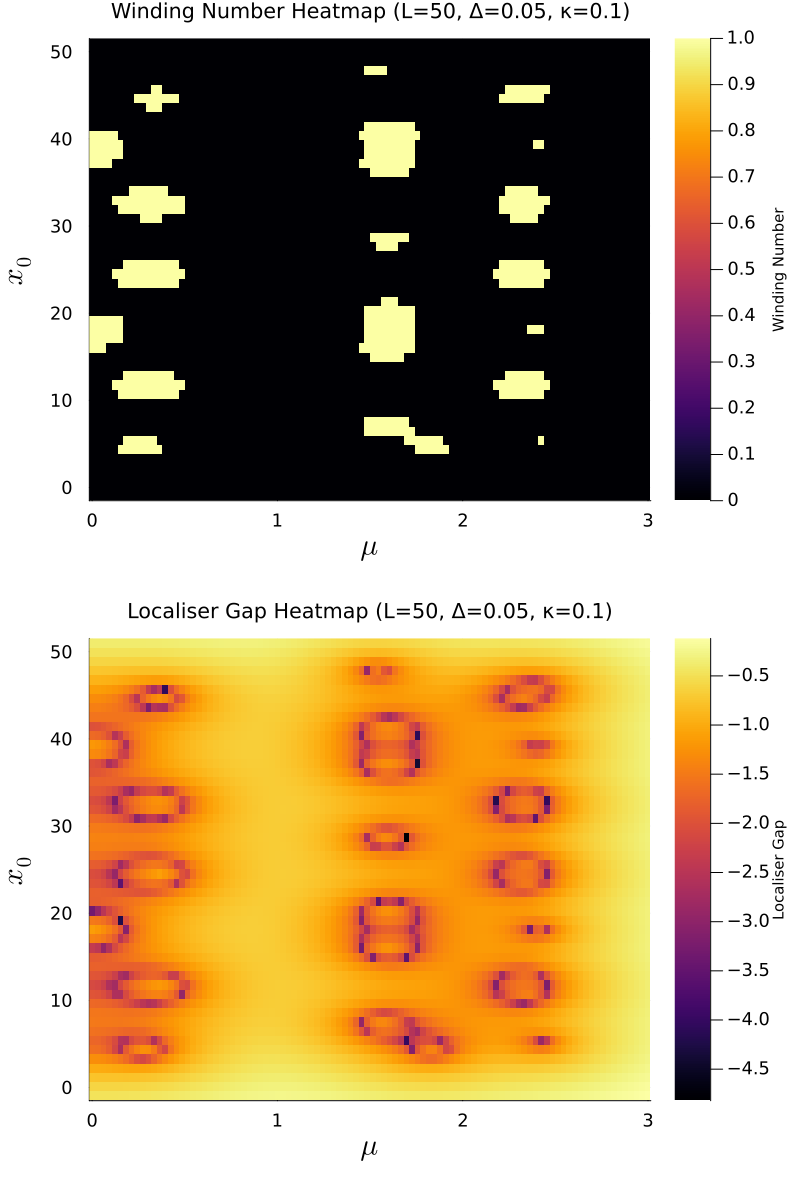

In [129]:
function heatmap_localiser_invariant_vs_mu_x0(
    df::DataFrame, 
    L::Int, 
    Delta::Float64, 
    kappa::Float64,
    filepath::String
)
    # Filter the DataFrame for the specified parameters
    df_filtered = filter(row -> row.Lx == L && row.Delta == Delta && row.kappa == kappa, df)

    # Extract mu and x values for axes
    mu_values = unique(df_filtered.mu)
    x_values = unique(df_filtered.x)

    winding_number = reshape(df_filtered.winding_number, length(x_values), length(mu_values))

    # Create the heatmap
    plt = Plots.heatmap(
        mu_values, 
        x_values, 
        winding_number, 
        xlabel=L"\mu", 
        ylabel=L"x_0", 
        title="Winding Number Heatmap (L=$L, Δ=$Delta, κ=$kappa)", 
        colorbar_title="Winding Number",
        size=(800, 600),
        labelfontsize=20,
        tickfontsize=12,
        legendfontsize=20,
        left_margin=5mm,
        bottom_margin=5mm
    )

    # Save the heatmap
    Plots.savefig(plt, filepath)
    display(plt)
end

function heatmap_localiser_inv_and_gap_vs_mu_x0(
    df::DataFrame, 
    L::Int, 
    Delta::Float64, 
    kappa::Float64,
    filepath::String
)
    # Filter the DataFrame for the specified parameters
    df_filtered = filter(row -> row.Lx == L && row.Delta == Delta && row.kappa == kappa, df)

    # Extract mu and x values for axes
    mu_values = unique(df_filtered.mu)
    x_values = unique(df_filtered.x)

    winding_number = reshape(df_filtered.winding_number, length(x_values), length(mu_values))
    localiser_gap = reshape(df_filtered.localiser_gap, length(x_values), length(mu_values))

    p1 = Plots.heatmap(
        mu_values, 
        x_values, 
        winding_number, 
        xlabel=L"\mu", 
        ylabel=L"x_0", 
        title="Winding Number Heatmap (L=$L, Δ=$Delta, κ=$kappa)", 
        colorbar_title="Winding Number",
        size=(800, 600),
        labelfontsize=20,
        tickfontsize=12,
        legendfontsize=20,
        left_margin=5mm,
        bottom_margin=5mm
    )

    p2 = Plots.heatmap(
        mu_values, 
        x_values, 
        log10.(localiser_gap),
        xlabel=L"\mu", 
        ylabel=L"x_0", 
        title="Localiser Gap Heatmap (L=$L, Δ=$Delta, κ=$kappa)", 
        colorbar_title="Localiser Gap",
        size=(800, 600),
        labelfontsize=20,
        tickfontsize=12,
        legendfontsize=20,
        left_margin=5mm,
        bottom_margin=5mm
    )

    plt = Plots.plot(p1, p2, layout=(2, 1), size=(800, 1200))

    # Save the heatmap
    Plots.savefig(plt, filepath)
    display(plt)
end

# Example usage:
L = 50
Delta = 0.05
kappa = 1e-1
filepath_heatmap_invariant_x0 = "heatmap_localiser_invariant_vs_mu_x0_L$(L)_Delta$(Delta)_kappa$(kappa).png"
# heatmap_localiser_invariant_vs_mu_x0(qc_dr_results, L, Delta, kappa, filepath_heatmap_invariant_x0)
heatmap_localiser_inv_and_gap_vs_mu_x0(qc_dr_results_invalid, L, Delta, kappa, "NEW_qc_outOfBounds_qc_heatmap_localiser_inv_and_gap_vs_mu_x0_L$(L)_Delta$(Delta)_kappa$(kappa).png")   


In [ ]:
L = 50
t_n = [1.0, 1.0]
Delta_vals = [0.05]
mu_vals = collect(range(0.0, 3.0, length=80))
kappa_vals = [1e-2] #logrange(1e-10, 1e2, length=13)

qc_dr_results = qc_compute_spec_loc_df_kitaev(
    L; 
    sequence=seq,
    t_n=t_n,
    Deltavals=Delta_vals, 
    muvals=mu_vals, 
    xs=L/2, #collect(range(-L, 2L, length=180)), 
    kappas=kappa_vals, 
    periodic=false, 
    sparse_output=true, 
    kk_tol=1e-8, 
    kk_maxiter=1000, 
    gap_tol=1e-6
)

println("Computed DataFrame of results:")

In [126]:
L = 50
t_n = [1.5, 1.0]
Delta_vals = [0.05]
mu_vals = collect(range(0.0, 3.0, length=100))
kappa_vals = [1e-1] #logrange(1e-10, 1e2, length=13)

# Use the BLOCK BASIS version (integrates with np_create_bdg_hamiltonian workflow)
qc_dr_results = qc_compute_spec_loc_df_block_basis(
    L; 
    sequence=seq,
    t_n=t_n,
    Deltavals=Delta_vals, 
    muvals=mu_vals, 
    xs=collect(range(-1, L+1, length=50)), 
    kappas=kappa_vals, 
    periodic=false, 
    sparse_output=true, 
    kk_tol=1e-8, 
    kk_maxiter=1000, 
    gap_tol=1e-6
)

println("Computed DataFrame of results:")


Computed DataFrame of results:


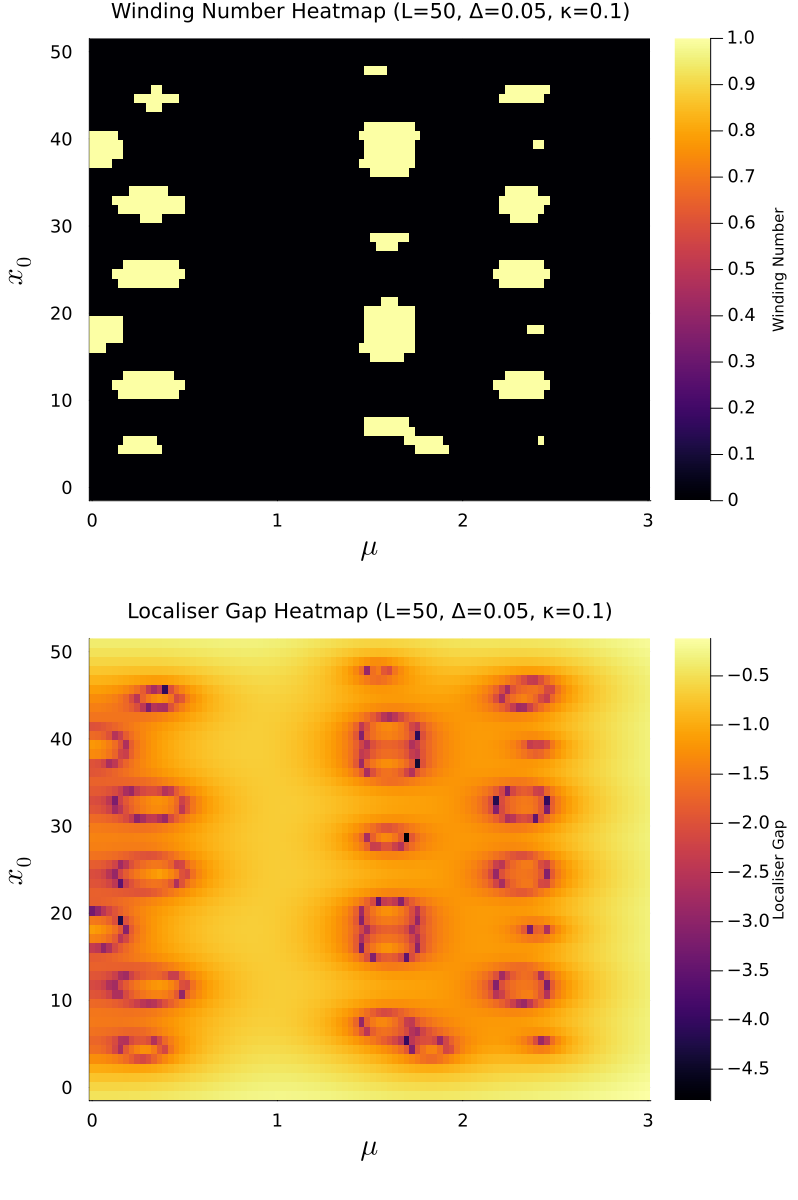

In [127]:

# Example usage:
L = 50
Delta = 0.05
kappa = 1e-1
filepath_heatmap_invariant_x0 = "heatmap_localiser_invariant_vs_mu_x0_L$(L)_Delta$(Delta)_kappa$(kappa).png"
# heatmap_localiser_invariant_vs_mu_x0(qc_dr_results, L, Delta, kappa, filepath_heatmap_invariant_x0)
heatmap_localiser_inv_and_gap_vs_mu_x0(qc_dr_results, L, Delta, kappa, "NEW_qc_outOfBounds_qc_heatmap_localiser_inv_and_gap_vs_mu_x0_L$(L)_Delta$(Delta)_kappa$(kappa).png")   


## Eigenvalues & MP